# In Candy Land, what is the expected probability distribution for the total number of turns required to reach Candy Castle, and what are its mean and standard deviation?

To solve this question, I will simulate multiple different number of turns it took to reach the Candy Castle which will be known as "(x)" and then I will calculate the probability of each number of times it took, which will be known as "P(x)". For example, if a player reached the Candy Castle in 26 and another player reached the Candy Castle in 17 turns, I will calculate the probability for the both of them and then proceed to use the mean and standard deviation formulas to fully answer my question. 

In [2]:
import random
import matplotlib.pyplot as plt
import pandas as pd

### Sample Round of Candy Land:

In [3]:
# Assigning values

boardColors = [
    "Red",
    "Purple",
    "Yellow",
    "Blue",
    "Orange",
    "Green",
] * 22 + ["Red", "Purple"]
specialSpaces = {
    "Plum": 9,
    "Peppermint": 20,
    "Peanut": 42,
    "Lolly": 69,
    "IceCream": 92,
    "Gumdrop": 102,
}


deckCards = []
for color in ["Red", "Purple", "Yellow", "Blue", "Orange", "Green"]:
    deckCards.extend([("single", color)] * 6)  
    deckCards.extend([("double", color)] * 4) 
for char in specialSpaces:
    deckCards.append(("special", char)) 

In [4]:
def simulate_single_game():
    position = 0
    turns = 0
    deck = deckCards.copy()
    random.shuffle(deck)

    while position < len(boardColors) - 1:
        turns += 1

     
        if not deck:
            deck = deckCards.copy()
            random.shuffle(deck)

        card_type, value = deck.pop()

        if card_type == "special":
        
            position = specialSpaces[value]
        elif card_type == "single":
          
            while position < len(boardColors) - 1:
                position += 1
                if boardColors[position] == value:
                    break
        elif card_type == "double":
        
            matches = 0
            while position < len(boardColors) - 1:
                position += 1
                if boardColors[position] == value:
                    matches += 1
                    if matches == 2:
                        break

    return turns

### Analysis:

In [5]:
num_simulations = 1000
turn_counts = [simulate_single_game() for _ in range(num_simulations)]

df = pd.DataFrame({"Turns_To_Win": turn_counts})

In [6]:
mean_turns = df["Turns_To_Win"].mean()
std_turns = df["Turns_To_Win"].std()

print(f"Mean turns to complete game: {mean_turns:.2f}")
print(f"Standard deviation: {std_turns:.2f}")


Mean turns to complete game: 28.97
Standard deviation: 15.33


### Visual:

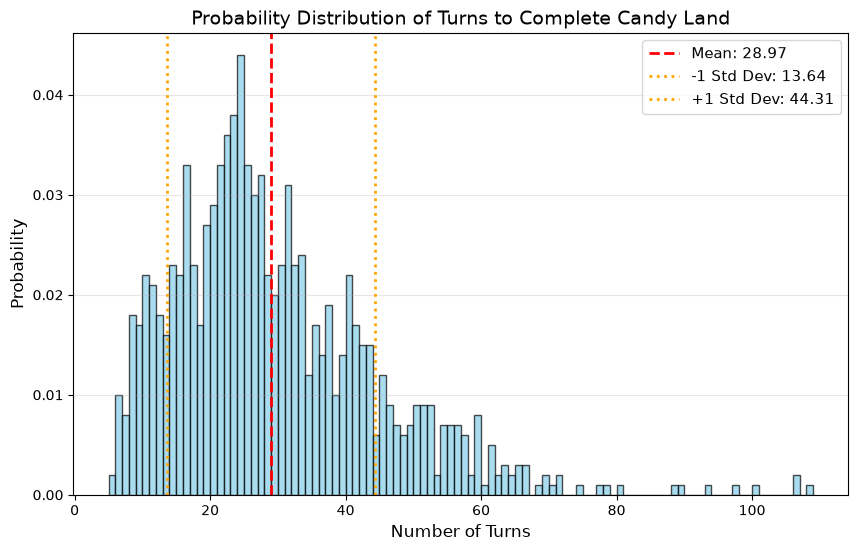

In [7]:
plt.figure(figsize=(10, 6))


count, bins, patches = plt.hist(
    df["Turns_To_Win"],
    bins=range(df["Turns_To_Win"].min(), df["Turns_To_Win"].max() + 2),
    density=True,
    color="skyblue",
    edgecolor="black",
    alpha=0.7,
)


plt.axvline(
    mean_turns,
    color="red",
    linestyle="dashed",
    linewidth=2,
    label=f"Mean: {mean_turns:.2f}",
)
plt.axvline(
    mean_turns - std_turns,
    color="orange",
    linestyle="dotted",
    linewidth=2,
    label=f"-1 Std Dev: {mean_turns - std_turns:.2f}",
)
plt.axvline(
    mean_turns + std_turns,
    color="orange",
    linestyle="dotted",
    linewidth=2,
    label=f"+1 Std Dev: {mean_turns + std_turns:.2f}",
)

plt.title(
    "Probability Distribution of Turns to Complete Candy Land", fontsize=14
)
plt.xlabel("Number of Turns", fontsize=12)
plt.ylabel("Probability", fontsize=12)
plt.legend(fontsize=11)
plt.grid(axis="y", alpha=0.3)
plt.show()

# Conclusion: 

After conducting 1,000 simulated rounds of Candy Land, I found out that the average (mean) number of turns it required to reach the Candy Castle was approximately 29 turns. The standard deviation took approximately 15 turns, meaning that most games are finished within 15 turns of the average. The histogram shows that the most common number of turns was closer to the mean whereas rounds that were too short or too long occurred less frequently. This distribution suggests that players can expect a round to typically end in around 29 turns. The graph supports this conclusion because the highest bars are clustered around the mean, showing that most simulated rounds took a similar number of turns to finish. The smaller bars at the ends of the graph indicate that unusually long or short rounds are less likely. 